<a href="https://colab.research.google.com/github/Abidau/MachineLearning/blob/main/TG6_244107020212_NaufalAbidAurizky.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Praktikum 1

### Percobaan 1

In [1]:
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 9.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520037 sha256=cce256546c4072218b73d1603aaa40b62be1f54298516067ec90f1345775821c
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


[euclidean | tree=3 | n=1000]
  Exact index : [219 898 593] | waktu: 9.8287 ms
  Annoy index : [219 898 593] | waktu: 0.0299 ms
  Recall      : 1.0


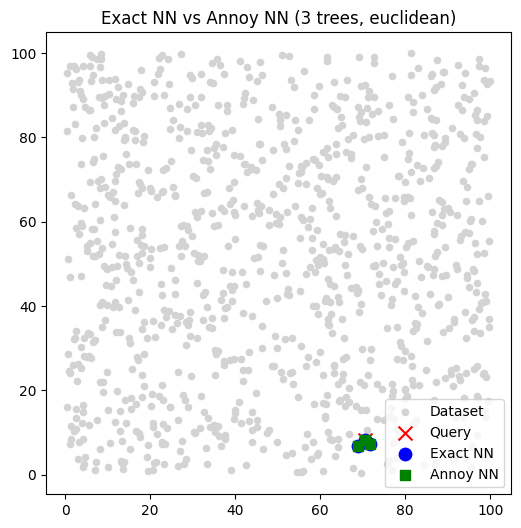

[euclidean | tree=8 | n=1000]
  Exact index : [219 898 593] | waktu: 0.2265 ms
  Annoy index : [219 898 593] | waktu: 0.0628 ms
  Recall      : 1.0


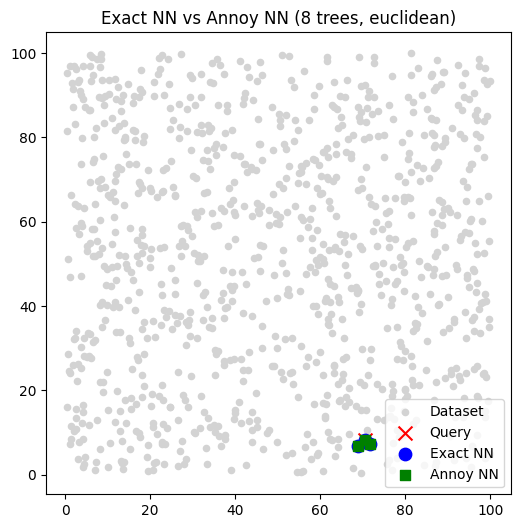

[euclidean | tree=3 | n=100000]
  Exact index : [64040 64186 88792] | waktu: 11.8632 ms
  Annoy index : [64040 64186 88792] | waktu: 0.042 ms
  Recall      : 1.0
[angular | tree=3 | n=1000]
  Exact index : [219 429 540] | waktu: 0.1936 ms
  Annoy index : [219 429 540] | waktu: 0.0364 ms
  Recall      : 1.0


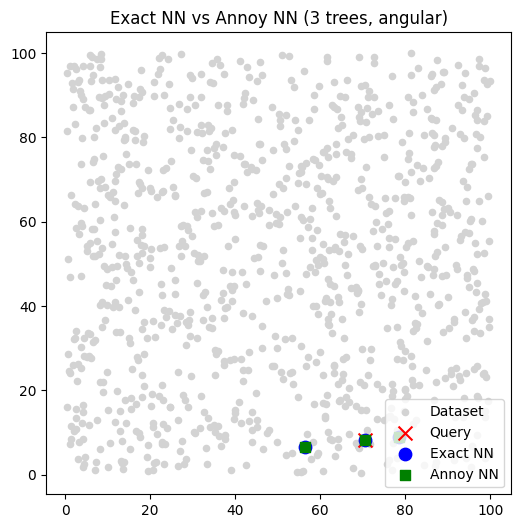

[angular | tree=8 | n=1000]
  Exact index : [219 429 540] | waktu: 0.3243 ms
  Annoy index : [219 429 540] | waktu: 0.0453 ms
  Recall      : 1.0


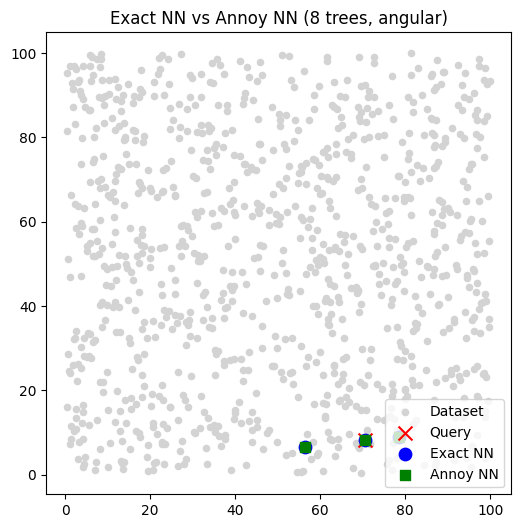

[angular | tree=3 | n=100000]
  Exact index : [64040  1310  1267] | waktu: 24.0059 ms
  Annoy index : [64040  1267  1310] | waktu: 0.051 ms
  Recall      : 1.0


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time
from annoy import AnnoyIndex

def run_experiment(n_points=1000, n_trees=3, metric='euclidean', k=3, plot=True):
    # 1. Dataset 2D (sama seperti modul, seed 42)
    np.random.seed(42)
    X = np.random.rand(n_points, 2) * 100
    query = X[np.random.randint(0, n_points)]

    # 2. Exact NN
    start = time.perf_counter()
    if metric == 'euclidean':
        distances = np.linalg.norm(X - query, axis=1)
    else:  # angular -> pakai cosine distance
        distances = 1 - (X @ query) / (np.linalg.norm(X, axis=1) * np.linalg.norm(query))
    idx_exact = np.argsort(distances)[:k]
    time_exact = time.perf_counter() - start

    # 3. Annoy NN
    t = AnnoyIndex(2, metric)
    t.set_seed(42)
    for i, vec in enumerate(X):
        t.add_item(i, vec)
    t.build(n_trees)

    start = time.perf_counter()
    idx_ann = t.get_nns_by_vector(query, k)
    time_ann = time.perf_counter() - start

    # 4. Recall: berapa NN exact yang juga ditemukan Annoy
    recall = len(set(idx_exact) & set(idx_ann)) / k

    print(f"[{metric} | tree={n_trees} | n={n_points}]")
    print("  Exact index :", idx_exact, "| waktu:", round(time_exact*1000, 4), "ms")
    print("  Annoy index :", np.array(idx_ann), "| waktu:", round(time_ann*1000, 4), "ms")
    print("  Recall      :", recall)

    if plot:
        plt.figure(figsize=(6, 6))
        plt.scatter(X[:, 0], X[:, 1], c="lightgray", s=20, label="Dataset")
        plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")
        plt.scatter(X[idx_exact, 0], X[idx_exact, 1], c="blue", s=80, label="Exact NN")
        plt.scatter(X[idx_ann, 0], X[idx_ann, 1], c="green", s=50, marker="s", label="Annoy NN")
        plt.legend()
        plt.title(f"Exact NN vs Annoy NN ({n_trees} trees, {metric})")
        plt.show()

# Jalankan 6 skenario sesuai tabel
run_experiment(1000, 3, 'euclidean')
run_experiment(1000, 8, 'euclidean')
run_experiment(100_000, 3, 'euclidean', plot=False)
run_experiment(1000, 3, 'angular')
run_experiment(1000, 8, 'angular')
run_experiment(100_000, 3, 'angular', plot=False)

In [3]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances, cosine_distances
from annoy import AnnoyIndex

def spotify_experiment(metric='euclidean', n_trees=8, n_tracks=1_000_000, n_features=20, k=5):
    np.random.seed(42)
    X = np.random.rand(n_tracks, n_features).astype(np.float32)
    query = np.random.rand(1, n_features).astype(np.float32)

    # ---- Exact NN ----
    start = time.time()
    if metric == 'euclidean':
        distances = euclidean_distances(query, X)[0]
    else:
        distances = cosine_distances(query, X)[0]
    exact_idx = np.argsort(distances)[:k]
    exact_time = time.time() - start

    # ---- Build index Annoy (waktu dicatat terpisah, hanya untuk info) ----
    start = time.time()
    annoy_index = AnnoyIndex(n_features, metric)
    annoy_index.set_seed(42)
    for i in range(n_tracks):
        annoy_index.add_item(i, X[i])
    annoy_index.build(n_trees)
    build_time = time.time() - start

    # ---- Query Annoy ----
    start = time.time()
    annoy_idx = annoy_index.get_nns_by_vector(query[0], k)
    annoy_time = time.time() - start

    recall = len(set(exact_idx) & set(annoy_idx)) / k
    print(f"[{metric} | tree={n_trees} | n={n_tracks}]")
    print("Exact NN :", exact_idx, "| waktu:", round(exact_time, 4), "detik")
    print("Annoy    :", np.array(annoy_idx), "| waktu:", round(annoy_time, 6), "detik")
    print("Recall   :", recall)
    print("(info) waktu build index:", round(build_time, 2), "detik")

spotify_experiment('euclidean', 8)
spotify_experiment('angular', 8)

[euclidean | tree=8 | n=1000000]
Exact NN : [229350 553886 763448 256344 308000] | waktu: 0.3298 detik
Annoy    : [852569 932735 664569 599618 386813] | waktu: 9.7e-05 detik
Recall   : 0.0
(info) waktu build index: 26.2 detik
[angular | tree=8 | n=1000000]
Exact NN : [308000 376840 229350 763448 553886] | waktu: 0.1926 detik
Annoy    : [308000 256344 386813 852569  70405] | waktu: 7.5e-05 detik
Recall   : 0.2
(info) waktu build index: 16.7 detik


## Praktikum 2

In [4]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 71.2 MB/s eta 0:00:00


Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.00016999244689941406
Waktu IVF+PQ: 0.0002570152282714844


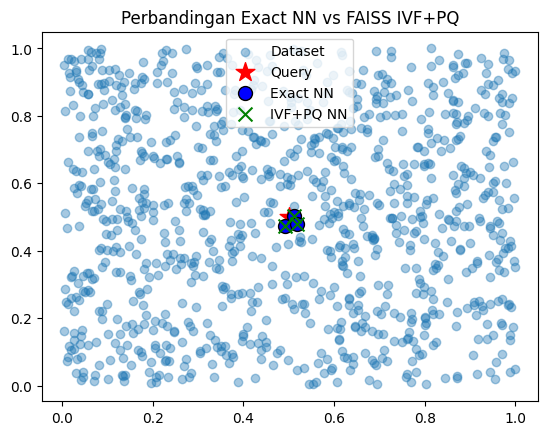

In [5]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()


## Praktikum 3

In [6]:
!pip install hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679799 sha256=d251fb29e348930f540578ace5be84c6d7034e6e584f90e081b10c45ceda7e59
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [7]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

=== Exact NN ===
Indices: [[830 247 473 913 592]]
Distances: [[0.00993625 0.01363944 0.01646171 0.03779694 0.03859071]]
Waktu: 0.052721500396728516 detik

=== HNSW ===
Indices: [[830 247 473 913 592]]
Distances: [[9.8728990e-05 1.8603441e-04 2.7098786e-04 1.4286089e-03 1.4892431e-03]]
Waktu: 0.00029730796813964844 detik


## Praktikum 4

In [8]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 37.16679358482361 detik
Query time: 0.0004379749298095703 detik
Neighbors: [129179, 559276, 630783, 213191, 559393] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.01920771598815918 detik
Query time: 0.026072263717651367 detik
Neighbors: [129179 559276 630783 213191 559393] ...

=== HNSW (hnswlib) ===
Build time: 182.45717477798462 detik
Query time: 0.0009427070617675781 detik
Neighbors: [129179 559276 630783 213191 559393] ...


## Praktikum 5

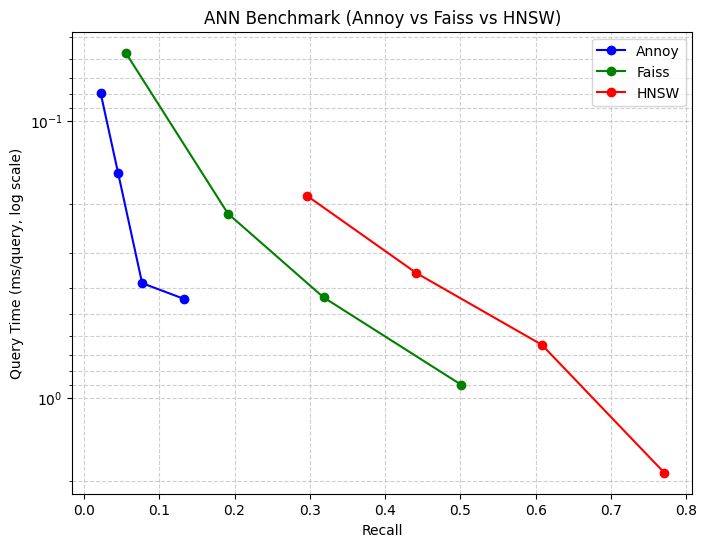

In [11]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## Praktikum 6

In [15]:
import os
import time
import numpy as np
import pandas as pd
import faiss
import hnswlib
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
path = '/content/songs_with_attributes_and_lyrics.csv'
if not os.path.exists(path):
    print("File tidak ditemukan. Isi folder /content saat ini:")
    print(os.listdir('/content'))
    raise FileNotFoundError(f"Cek nama/lokasi file: {path}")

df = pd.read_csv(path)
print("Ukuran dataset:", df.shape)

features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

# Cek apakah semua kolom fitur ada di dataset
missing = [c for c in features if c not in df.columns]
if missing:
    print("Kolom tidak ditemukan:", missing)
    print("Kolom yang tersedia:", list(df.columns))
    raise KeyError(f"Sesuaikan list 'features' dengan kolom dataset: {missing}")

# Buang baris yang punya nilai kosong di fitur
df = df.dropna(subset=features).reset_index(drop=True)

# Standarisasi fitur, lalu ubah ke float32
X_scaled = StandardScaler().fit_transform(df[features].values).astype('float32')
n, f = X_scaled.shape
k = 10
print(f"Jumlah lagu: {n}, jumlah fitur: {f}")

results = {}

def recall_at_k(approx, exact):
    return np.mean([len(set(a) & set(e)) / k for a, e in zip(approx, exact)])

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
t0 = time.perf_counter()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
build_exact = time.perf_counter() - t0

t0 = time.perf_counter()
dist_exact, idx_exact = nn.kneighbors(X_scaled)
query_exact = time.perf_counter() - t0
results['Exact NN'] = (build_exact, query_exact, 1.0)

# -------------------------------
# Annoy
# -------------------------------
t0 = time.perf_counter()
index_annoy = AnnoyIndex(f, 'euclidean')
index_annoy.set_seed(42)
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
build_annoy = time.perf_counter() - t0

t0 = time.perf_counter()
idx_annoy = np.array([index_annoy.get_nns_by_vector(v, k) for v in X_scaled])
query_annoy = time.perf_counter() - t0
results['Annoy'] = (build_annoy, query_annoy, recall_at_k(idx_annoy, idx_exact))

# -------------------------------
# HNSW
# -------------------------------
t0 = time.perf_counter()
p_hnsw = hnswlib.Index(space='l2', dim=f)
p_hnsw.init_index(max_elements=n, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
build_hnsw = time.perf_counter() - t0

t0 = time.perf_counter()
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
query_hnsw = time.perf_counter() - t0
results['HNSW'] = (build_hnsw, query_hnsw, recall_at_k(idx_hnsw, idx_exact))

# -------------------------------
# FAISS IVF
# -------------------------------
t0 = time.perf_counter()
quantizer = faiss.IndexFlatL2(f)
index_faiss = faiss.IndexIVFFlat(quantizer, f, 100, faiss.METRIC_L2)  # nlist=100
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
build_faiss = time.perf_counter() - t0

t0 = time.perf_counter()
dist_faiss, idx_faiss = index_faiss.search(X_scaled, k)
query_faiss = time.perf_counter() - t0
results['FAISS IVF'] = (build_faiss, query_faiss, recall_at_k(idx_faiss, idx_exact))

# -------------------------------
# Ringkasan
# -------------------------------
summary = pd.DataFrame(results, index=['Build (s)', 'Query (s)', 'Recall@10']).T
print("\n", summary.round(4))

# -------------------------------
# Contoh neighbors lagu pertama
# -------------------------------
print("\nTop-5 neighbors untuk lagu pertama (indeks pertama = lagu itu sendiri):")
print("Exact NN:", idx_exact[0][:5])
print("Annoy   :", idx_annoy[0][:5])
print("HNSW    :", idx_hnsw[0][:5])
print("FAISS   :", idx_faiss[0][:5])

if 'name' in df.columns:
    print("\nLagu query:", df.loc[0, 'name'])
    print("Tetangga (Exact):", df.loc[idx_exact[0][1:6], 'name'].tolist())

Ukuran dataset: (254359, 17)
Jumlah lagu: 254358, jumlah fitur: 9

            Build (s)  Query (s)  Recall@10
Exact NN      0.0067   392.7344     1.0000
Annoy         3.9748    13.2953     0.8540
HNSW         48.2470    39.8263     0.9956
FAISS IVF     0.1437    81.8250     0.9979

Top-5 neighbors untuk lagu pertama (indeks pertama = lagu itu sendiri):
Exact NN: [     0  61511  85956 240692 216265]
Annoy   : [     0  61511 216265   3836 209597]
HNSW    : [     0  61511  85956 240692 216265]
FAISS   : [     0  61511  85956 240692 216265]

Lagu query: !
Tetangga (Exact): ['Autumn Interlude', 'Bewitched', 'Evergreen', 'Dunkelheit', '1000 Dollar Car']


## Tugas

In [18]:
import numpy as np
import time
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur, lalu kembalikan ke float32 (wajib untuk FAISS)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')

k = 10  # jumlah nearest neighbors
results = {}

def recall_at_k(approx, exact):
    return np.mean([len(set(a) & set(e)) / k for a, e in zip(approx, exact)])

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.perf_counter()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.perf_counter() - start
print(f"Exact NN done in {time_exact:.3f} s")
results['Exact NN'] = (time_exact, 1.0)

# -------------------------------
# Annoy
# -------------------------------
start = time.perf_counter()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
index_annoy.set_seed(42)
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = np.array([index_annoy.get_nns_by_vector(v, k) for v in X_scaled])
time_annoy = time.perf_counter() - start
print(f"Annoy done in {time_annoy:.3f} s")
results['Annoy'] = (time_annoy, recall_at_k(idx_annoy, idx_exact))

# -------------------------------
# HNSW
# -------------------------------
start = time.perf_counter()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.perf_counter() - start
print(f"HNSW done in {time_hnsw:.3f} s")
results['HNSW'] = (time_hnsw, recall_at_k(idx_hnsw, idx_exact))

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.perf_counter()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)  # nlist=100 (posisi, bukan keyword)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.perf_counter() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")
results['FAISS IVF'] = (time_faiss, recall_at_k(idx_faiss, idx_exact))

# -------------------------------
# Tampilkan ringkasan waktu + recall
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

print("\n=== Ringkasan Lengkap ===")
print(pd.DataFrame(results, index=['Waktu total (s)', 'Recall@10']).T.round(4))

Exact NN done in 2.247 s
Annoy done in 1.194 s
HNSW done in 5.568 s
FAISS IVF done in 0.379 s

=== Ringkasan Waktu (detik) ===
Exact NN : 2.247
Annoy    : 1.194
HNSW     : 5.568
FAISS    : 0.379

=== Ringkasan Lengkap ===
           Waktu total (s)  Recall@10
Exact NN            2.2473     1.0000
Annoy               1.1944     0.1667
HNSW                5.5677     0.9805
FAISS IVF           0.3788     0.4182
